# ACME Talent Insights

**Audience:** HR leaders, managers and the data team.

This notebook answers ACME's 7 workforce questions using the **Gold layer** of the data lake
built by the `talent-etl` pipeline (`data/talent-etl/job.py`).

```
PostgreSQL (HR tables) ─┐
                        ├─► Bronze (raw) ─► Silver (clean, validated) ─► Gold (answers) ─► this notebook
S3 (learning events) ───┘
```

**How to run:** run the pipeline first (`python3 data/talent-etl/job.py`), then *Kernel → Restart & Run All*.

| # | Business question | Gold table |
|---|---|---|
| 1 | What are the performance ratings and review history for each employee? | `employee_review_history` |
| 2 | Which employees have critical skill gaps? | `skill_gaps` |
| 3 | Who are the high-potential employees ready for promotion? | `promotion_pipeline` |
| 4 | What training has each employee completed? | `training_summary` |
| 5 | Which employees are at risk of attrition? | `attrition_risk` |
| 6 | How does performance correlate with team & project outcomes? | `team_performance` |
| 7 | What is the distribution of skills across the organization? | `skill_distribution` |

## 0. Setup: connect to the data lake

In [39]:
import io
import json
import os

import boto3
import matplotlib.pyplot as plt
import pandas as pd
from botocore.config import Config

# Same environment variables as the pipeline. Defaults = local LocalStack.
BUCKET = os.getenv("DATALAKE_BUCKET", "acme-datalake")
ENDPOINT = os.getenv("AWS_ENDPOINT_URL", "http://localhost.localstack.cloud:4566") or None
os.environ.setdefault("AWS_ACCESS_KEY_ID", "test")
os.environ.setdefault("AWS_SECRET_ACCESS_KEY", "test")
os.environ.setdefault("AWS_DEFAULT_REGION", "us-east-1")

s3 = boto3.client("s3", endpoint_url=ENDPOINT, config=Config(s3={"addressing_style": "path"}))


def list_keys(prefix):
    pages = s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=prefix)
    return sorted(o["Key"] for p in pages for o in p.get("Contents", []))


def load_gold(name):
    """Load one Gold table (all Parquet files under gold/<name>/) into a DataFrame."""
    keys = [k for k in list_keys(f"gold/{name}/") if k.endswith(".parquet")]
    return pd.concat([pd.read_parquet(io.BytesIO(s3.get_object(Bucket=BUCKET, Key=k)["Body"].read()))
                      for k in keys], ignore_index=True)


# Chart style: one consistent, colour-blind-safe palette
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10})
pd.set_option("display.max_columns", 20, "display.width", 160)

gold = {name: load_gold(name) for name in [
    "employee_review_history", "skill_gaps", "promotion_pipeline", "training_summary",
    "attrition_risk", "team_performance", "skill_distribution"]}
pd.DataFrame({"rows": {k: len(v) for k, v in gold.items()}})

,rows
employee_review_history,4000
skill_gaps,4000
promotion_pipeline,2000
training_summary,2000
attrition_risk,2000
team_performance,100
skill_distribution,200


## Pipeline health (data lineage)

Before trusting the numbers, check the latest pipeline run: how many rows came in, how many were
cleaned out, and whether every reconciliation check passed.

In [38]:
latest = list_keys("_lineage/")[-1]
manifest = json.loads(s3.get_object(Bucket=BUCKET, Key=latest)["Body"].read())
checks = pd.DataFrame(manifest["reconciliation_checks"])
print(f"Run {manifest['run_id']}  status={manifest['status']}  duration={manifest['duration_seconds']}s")
print(f"Reconciliation checks passed: {checks['passed'].sum()} / {len(checks)}")

silver = pd.DataFrame([m for m in manifest["metrics"] if m["layer"] == "silver"]).set_index("dataset")
silver[["read", "valid", "rejected", "duplicates_removed"]]

Run 20261015T050733Z-3b74bb  status=SUCCESS  duration=7.79s
Reconciliation checks passed: 16 / 16


,read,valid,rejected,duplicates_removed
dataset,,,,
teams,100,100,0,0
competencies,40,40,0,0
employees,2000,2000,0,0
projects,33,33,0,0
performance_reviews,4000,4000,0,0
competency_assessments,4000,4000,0,0
talent_review,2000,2000,0,0
learning_activity,29868,29574,143,151


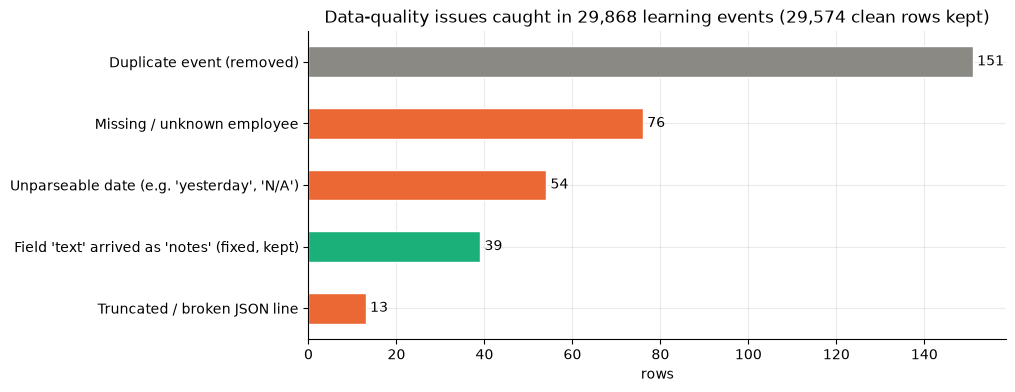

In [3]:
la = silver.loc["learning_activity"]
qkey = [k for k in list_keys("quarantine/learning_activity/") if k.endswith(".jsonl")][-1]
reasons = [json.loads(line)["reject_reason"] for line in
           s3.get_object(Bucket=BUCKET, Key=qkey)["Body"].read().decode().splitlines()]

def reason_label(r):
    if r.startswith("malformed_json"): return "Truncated / broken JSON line"
    if "event_date" in r: return "Unparseable date (e.g. 'yesterday', 'N/A')"
    if "employee_id" in r: return "Missing / unknown employee"
    return "Other schema violation"

issues = pd.Series([reason_label(r) for r in reasons]).value_counts()
issues["Duplicate event (removed)"] = int(la["duplicates_removed"])
issues["Field 'text' arrived as 'notes' (fixed, kept)"] = int(la["schema_drift_mapped"])
issues = issues.sort_values()
colors = [AQUA if "fixed" in i else GREY if "Duplicate" in i else ORANGE for i in issues.index]
ax = issues.plot(kind="barh", color=colors, edgecolor="white")
ax.set_title(f"Data-quality issues caught in {int(la['read']):,} learning events "
             f"({int(la['valid']):,} clean rows kept)")
ax.set_xlabel("rows")
for i, v in enumerate(issues): ax.text(v + 1, i, str(v), va="center")
plt.show()

**What this shows:** the HR database tables were clean (0 rejects). The learning-event files were not:
the pipeline caught **13 truncated JSON lines, 54 unparseable dates (`"yesterday"`, `"N/A"`, empty),
76 events with no employee**, removed **151 duplicate events**, and fixed **39 events** where the
field `text` had been renamed to `notes` (schema drift). Rejected rows are kept in
`quarantine/` for troubleshooting, not deleted.

## Q1. What are the performance ratings and review history for each employee?

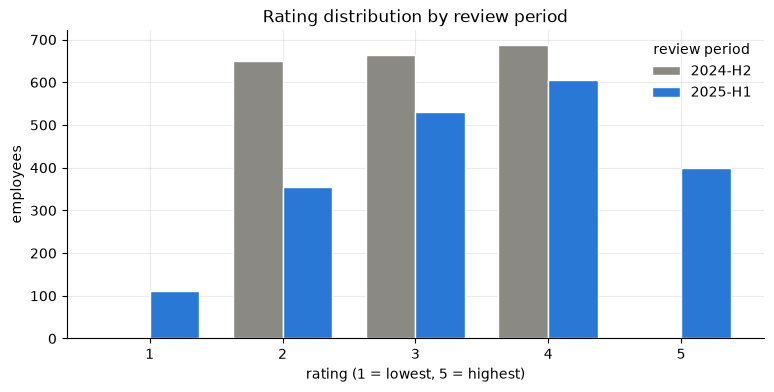

,mean,count,share rated 4-5 (%)
review_period,,,
2024-H2,3.02,2000,34.4
2025-H1,3.41,2000,50.2


In [25]:
hist = gold["employee_review_history"]
dist = hist.pivot_table(index="rating", columns="review_period", values="employee_id", aggfunc="count").fillna(0)
ax = dist.plot(kind="bar", color=[GREY, BLUE], edgecolor="white", width=0.75)
ax.set_title("Rating distribution by review period")
ax.set_xlabel("rating (1 = lowest, 5 = highest)"); ax.set_ylabel("employees"); ax.tick_params(axis="x", rotation=0)
ax.legend(title="review period", frameon=False)
plt.show()

summary = hist.groupby("review_period")["rating"].agg(["mean", "count"]).round(2)
summary["share rated 4-5 (%)"] = hist.groupby("review_period")["rating"].apply(lambda s: round((s >= 4).mean() * 100, 1))
summary

In [26]:
change = hist.dropna(subset=["rating_change"])["rating_change"]
print(f"Improved: {(change > 0).sum()}   Same: {(change == 0).sum()}   Declined: {(change < 0).sum()}")

# Look up any employee's full history
EMPLOYEE_ID = 1
hist[hist["employee_id"] == EMPLOYEE_ID]

Improved: 898   Same: 872   Declined: 230


,employee_id,employee_name,team_name,department,job_level,review_period,rating,previous_rating,rating_change,manager_comment,submitted_date
0,1,Heather Davis,Team LightYellow-1,Sales,Director,2024-H2,3,NaN,NaN,Delivered on commitments with no major concerns.,2025-08-31
1,1,Heather Davis,Team LightYellow-1,Sales,Director,2025-H1,4,3.0,1.0,Delivered on commitments with no major concerns.,2026-02-27


**Answer:** every employee has two reviews (2024-H2 and 2025-H1). The average rating rose from
**3.02 to 3.41**, and the share rated 4–5 grew from **34% to 50%**. Between the two periods
**898 employees improved, 872 stayed the same and 230 declined**. Use the lookup cell above
(change `EMPLOYEE_ID`) to see any individual's history, including rating change and manager comment.

## Q2. Which employees have critical skill gaps in key competencies?

**Definition:** `gap = required_level - proficiency_level`. A gap of **2 or more levels** is *critical*.

Assessments with any gap: 993 of 4,000
Critical gaps: 325 affecting 317 employees


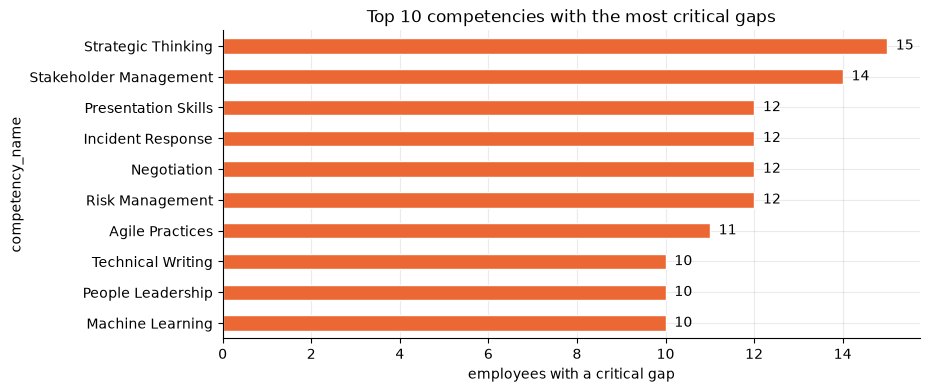

In [27]:
gaps = gold["skill_gaps"]
critical = gaps[gaps["is_critical_gap"]]
print(f"Assessments with any gap: {gaps['has_gap'].sum():,} of {len(gaps):,}")
print(f"Critical gaps: {len(critical):,} affecting {critical['employee_id'].nunique():,} employees")

top = critical["competency_name"].value_counts().head(10).sort_values()
ax = top.plot(kind="barh", color=ORANGE, edgecolor="white")
ax.set_title("Top 10 competencies with the most critical gaps"); ax.set_xlabel("employees with a critical gap")
for i, v in enumerate(top): ax.text(v + 0.2, i, str(v), va="center")
plt.show()

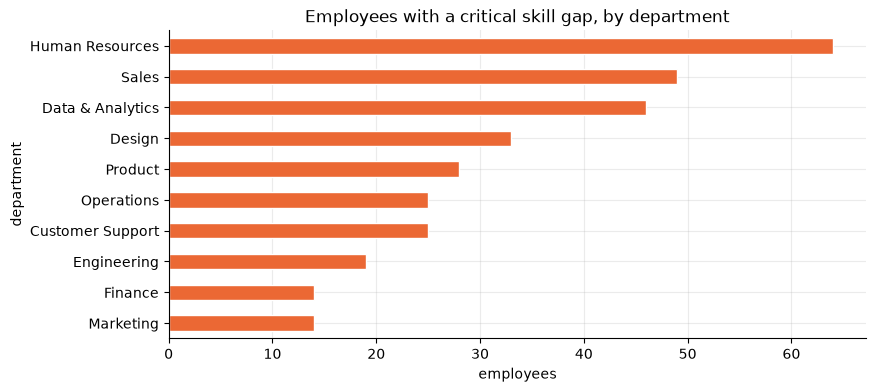

,employee_id,employee_name,department,competency_name,proficiency_level,required_level,gap
2,2,Kristie Heath,Sales,Strategic Thinking,2,4,2
8,5,Linda Murray,Sales,Machine Learning,1,3,2
20,11,Natalie Wallace,Sales,Coaching & Mentoring,1,3,2
36,19,Kaylee Reid,Design,People Leadership,1,3,2
60,31,Douglas Salinas,Design,Data Privacy,2,4,2
65,33,Madison Kirby,Design,Security Fundamentals,1,3,2
74,38,David Gonzalez,Design,Data Modeling,1,3,2
78,40,Lindsey Harris,Design,People Leadership,2,4,2
97,49,Brandon Weiss,Sales,Machine Learning,1,3,2
103,52,Kelly Smith,Sales,Agile Practices,2,4,2


In [30]:
by_dept = critical.groupby("department")["employee_id"].nunique().sort_values()
ax = by_dept.plot(kind="barh", color=ORANGE, edgecolor="white")
ax.set_title("Employees with a critical skill gap, by department"); ax.set_xlabel("employees")
plt.show()

# Employees with the largest gaps (action list for managers)
critical.sort_values("gap", ascending=False)[
    ["employee_id", "employee_name", "department", "competency_name", "proficiency_level", "required_level", "gap"]].head(15)

**Answer:** **25% of assessments (993)** show some gap, and **8% (325)** are critical, affecting
**317 employees**. The most common critical gaps are in **Strategic Thinking** and
**Stakeholder Management** (which is also the weakest competency overall, see Q7). The table above is a ready-made action list for training plans.

## Q3. Who are the high-potential employees ready for promotion?

**Definition:** *promotion-ready* = potential rating **High** + promotion readiness **Ready Now** +
latest performance rating **4 or 5**.

High-potential employees: 646
Promotion-ready (high potential + ready now + rating >= 4): 166


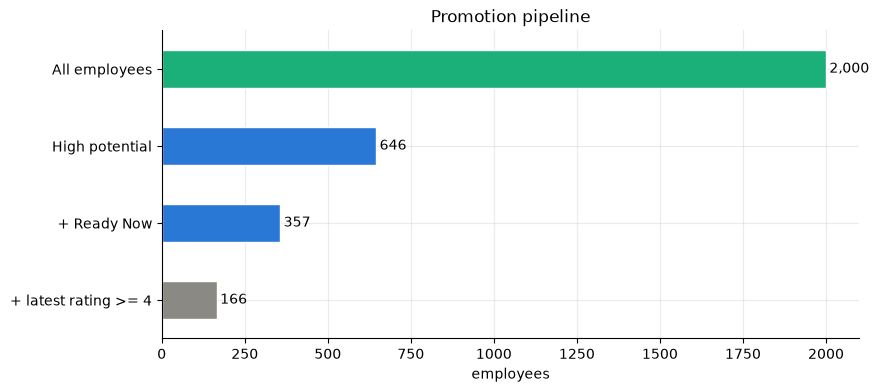

In [31]:
promo = gold["promotion_pipeline"]
ready = promo[promo["is_promotion_ready"]]
print(f"High-potential employees: {promo['is_high_potential'].sum():,}")
print(f"Promotion-ready (high potential + ready now + rating >= 4): {len(ready):,}")

funnel = pd.Series({
    "All employees": len(promo),
    "High potential": int(promo["is_high_potential"].sum()),
    "+ Ready Now": int((promo["is_high_potential"] & promo["promotion_readiness"].eq("Ready Now")).sum()),
    "+ latest rating >= 4": len(ready),
})
ax = funnel[::-1].plot(kind="barh", color=[AQUA, BLUE, BLUE, GREY][::-1], edgecolor="white")
ax.set_title("Promotion pipeline"); ax.set_xlabel("employees")
for i, v in enumerate(funnel[::-1]): ax.text(v + 10, i, f"{v:,}", va="center")
plt.show()

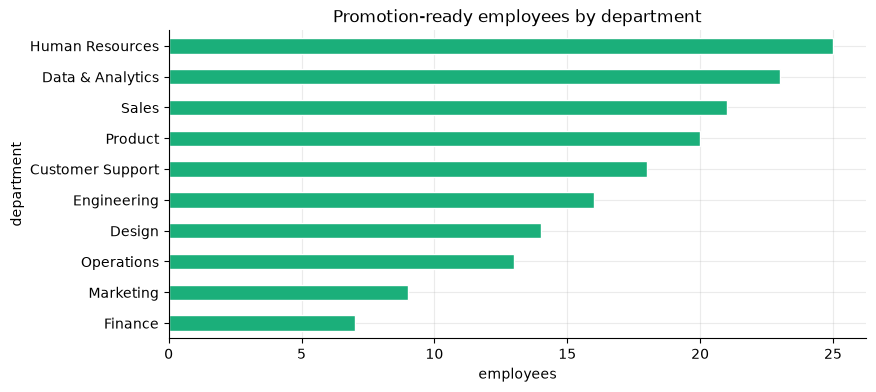

,employee_id,employee_name,department,job_level,latest_rating,avg_rating,rating_trend
83,84,Daniel Osborne,Customer Support,Manager,5,4.5,1
95,96,Jacob Jordan,Customer Support,Manager,5,4.5,1
136,137,Victoria Briggs,Product,Manager,5,4.5,1
144,145,Lisa Johnson,Product,Manager,5,4.5,1
241,242,Amanda Harper,Customer Support,IC1,5,4.5,1
247,248,Lindsey Gonzales,Customer Support,Senior Manager,5,4.5,1
267,268,Heather Bowman,Engineering,IC2,5,4.5,1
271,272,Paul Smith,Engineering,IC3,5,4.5,1
358,359,Cameron Williams,Data & Analytics,Manager,5,4.5,1
390,391,Patrick Harris,Product,Senior Manager,5,4.5,1


In [34]:
ax = ready["department"].value_counts().sort_values().plot(kind="barh", color=AQUA, edgecolor="white")
ax.set_title("Promotion-ready employees by department"); ax.set_xlabel("employees")
plt.show()

ready.sort_values(["latest_rating", "avg_rating"], ascending=False)[
    ["employee_id", "employee_name", "department", "job_level", "latest_rating", "avg_rating", "rating_trend"]].head(15)

**Answer:** **646 employees** are rated high-potential, but only **166** meet all three conditions
and are ready for promotion now. The table lists the strongest candidates for succession planning.

## Q4. What training and development activities has each employee completed?

Employees with any learning activity: 2,000 of 2,000
Courses completed (total): 3,421   Certifications earned: 1,764


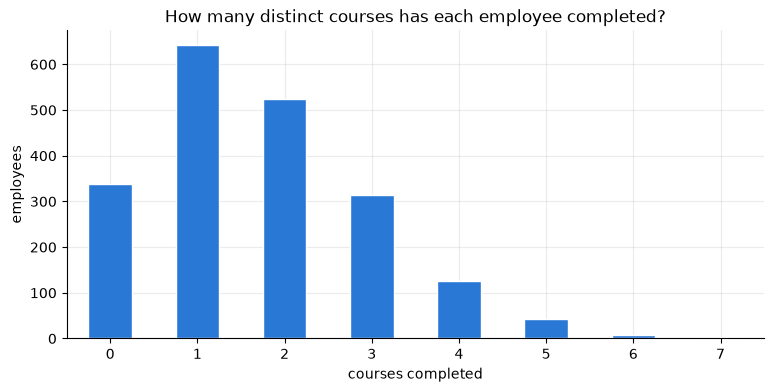

In [35]:
train = gold["training_summary"]
print(f"Employees with any learning activity: {(train['total_events'] > 0).sum():,} of {len(train):,}")
print(f"Courses completed (total): {train['courses_completed'].sum():,}   Certifications earned: {train['certifications_earned'].sum():,}")

ax = train["courses_completed"].value_counts().sort_index().plot(kind="bar", color=BLUE, edgecolor="white")
ax.set_title("How many distinct courses has each employee completed?")
ax.set_xlabel("courses completed"); ax.set_ylabel("employees"); ax.tick_params(axis="x", rotation=0)
plt.show()

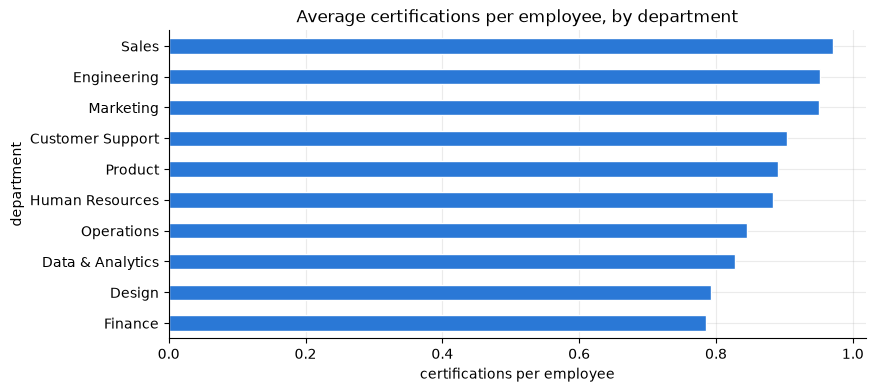

,0
employee_id,1
employee_name,Heather Davis
job_level,Director
hire_date,2024-04-06
team_id,1
team_name,Team LightYellow-1
department,Sales
total_events,20
enrollments,2
modules_completed,1


In [36]:
cert = train.groupby("department")["certifications_earned"].mean().sort_values()
ax = cert.plot(kind="barh", color=BLUE, edgecolor="white")
ax.set_title("Average certifications per employee, by department"); ax.set_xlabel("certifications per employee")
plt.show()

# Per-employee record (change the id)
EMPLOYEE_ID = 1
train[train["employee_id"] == EMPLOYEE_ID].T

**Answer:** every employee has some learning activity. The pipeline records, per employee, enrollments,
modules and courses completed (with course names), quizzes passed, average quiz score and
certifications. Use the lookup cell above for any individual's training record.

## Q5. Which employees are at risk of attrition based on performance trends?

**Risk score** (0–5) = HR attrition flag (Low 0 / Medium 1 / High 2)
+ 1 if the rating **went down** + 1 if the latest rating is **2 or lower** + 1 if the latest manager comment is **negative**.
Band: **High ≥ 4**, Medium 2–3, Low 0–1.

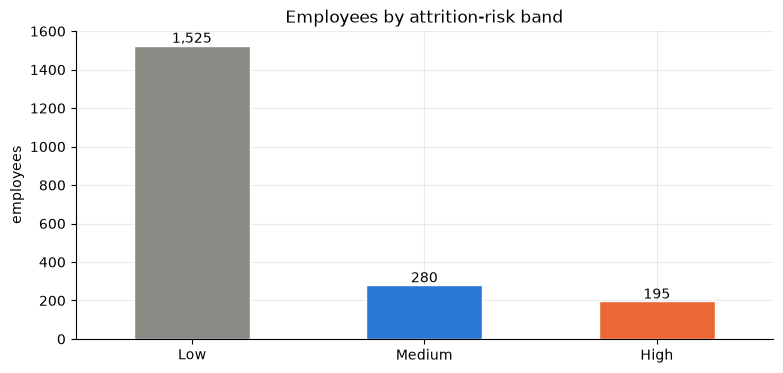

Of the High-risk band:
  declining rating: 100%   latest rating <= 2: 89%   negative comment: 100%


In [18]:
risk = gold["attrition_risk"]
bands = risk["risk_band"].value_counts().reindex(["Low", "Medium", "High"])
ax = bands.plot(kind="bar", color=[GREY, BLUE, ORANGE], edgecolor="white")
ax.set_title("Employees by attrition-risk band"); ax.set_ylabel("employees"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(bands): ax.text(i, v + 15, f"{v:,}", ha="center")
plt.show()

print("Of the High-risk band:")
high = risk[risk["risk_band"] == "High"]
print(f"  declining rating: {high['declining_performance'].mean():.0%}   latest rating <= 2: {high['low_latest_rating'].mean():.0%}"
      f"   negative comment: {high['negative_manager_comment'].mean():.0%}")

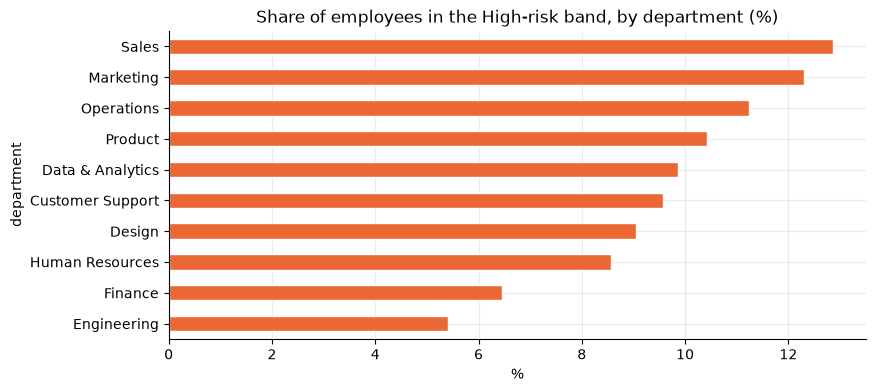

High-risk AND high-potential employees: 65


,employee_id,employee_name,department,previous_rating,latest_rating,attrition_risk,risk_score,latest_comment
48,49,Brandon Weiss,Sales,2,1,High,5,Struggled to meet deadlines; follow-up plan re...
1665,1666,Jennifer Watson,Data & Analytics,2,1,High,5,Struggled to meet deadlines; follow-up plan re...
122,123,Matthew Keller,Finance,2,1,High,5,Missed several key deliverables this cycle; ne...
245,246,Brian Jones,Customer Support,2,1,High,5,Struggled to meet deadlines; follow-up plan re...
244,245,Karen Rosales,Customer Support,4,2,High,5,Struggled to meet deadlines; follow-up plan re...
255,256,Jeffrey Santana,Marketing,3,2,High,5,Missed several key deliverables this cycle; ne...
294,295,Paula Davies,Product,3,1,High,5,Struggled to meet deadlines; follow-up plan re...
360,361,Desiree Robertson,Data & Analytics,3,1,High,5,Engagement and output have both trended down.
307,308,Samuel Harris,Product,3,2,High,5,Engagement and output have both trended down.
520,521,Charles Smith,Operations,3,1,High,5,Missed several key deliverables this cycle; ne...


In [19]:
pct_high = risk.groupby("department")["risk_band"].apply(lambda s: (s == "High").mean() * 100).sort_values()
ax = pct_high.plot(kind="barh", color=ORANGE, edgecolor="white")
ax.set_title("Share of employees in the High-risk band, by department (%)"); ax.set_xlabel("%")
plt.show()

# Most urgent: high-risk employees who are ALSO high-potential (regretted attrition)
urgent = high[high["potential_rating"] == "High"]
print(f"High-risk AND high-potential employees: {len(urgent)}")
urgent.sort_values("risk_score", ascending=False)[
    ["employee_id", "employee_name", "department", "previous_rating", "latest_rating", "attrition_risk", "risk_score", "latest_comment"]].head(15)

**Answer:** **195 employees** fall in the High-risk band and **280** in Medium. Every High-risk employee
had a **declining rating and a negative manager comment**. **Sales** and **Marketing** have the highest
share at risk. The most urgent group is the **65 high-risk employees who are also high-potential**. Losing them would hurt most, so managers
should start retention conversations with this list.

## Q6. How does employee performance correlate with team and project outcomes?

Teams with projects: 27 of 100   Pearson r (avg rating vs avg project score) = 0.24


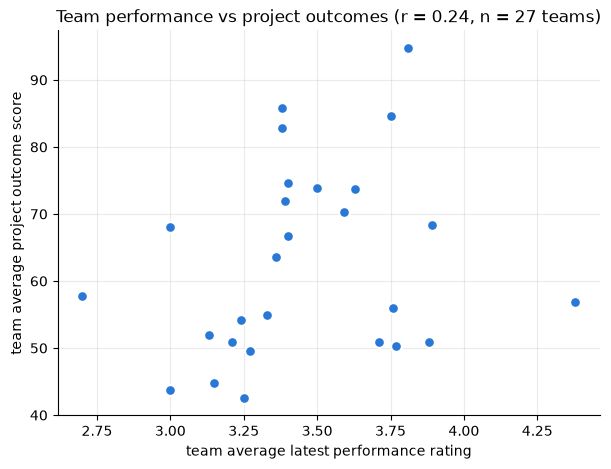

In [20]:
teams = gold["team_performance"]
with_projects = teams[teams["project_count"] > 0]
r = with_projects["avg_latest_rating"].corr(with_projects["avg_project_score"])
print(f"Teams with projects: {len(with_projects)} of {len(teams)}   Pearson r (avg rating vs avg project score) = {r:.2f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(with_projects["avg_latest_rating"], with_projects["avg_project_score"], s=60, color=BLUE,
           edgecolor="white", linewidth=1.5)
ax.set_xlabel("team average latest performance rating"); ax.set_ylabel("team average project outcome score")
ax.set_title(f"Team performance vs project outcomes (r = {r:.2f}, n = {len(with_projects)} teams)")
plt.show()

In [21]:
cmp = with_projects.groupby(with_projects["pct_projects_on_time"] >= 50)["avg_latest_rating"].mean().round(2)
cmp.index = cmp.index.map({True: "mostly on-time teams", False: "mostly delayed teams"})
print(cmp.to_string())
teams.sort_values("avg_project_score", ascending=False)[
    ["team_name", "department", "headcount", "avg_latest_rating", "pct_high_performers", "project_count", "avg_project_score", "pct_projects_on_time"]].head(10)

pct_projects_on_time
mostly delayed teams    3.17
mostly on-time teams    3.55


,team_name,department,headcount,avg_latest_rating,pct_high_performers,project_count,avg_project_score,pct_projects_on_time
88,Team YellowGreen-89,Human Resources,21,3.81,61.90,1,94.76,100.0
12,Team Moccasin-13,Customer Support,26,3.38,53.85,1,85.79,100.0
33,Team GreenYellow-34,Operations,12,3.75,66.67,1,84.68,100.0
86,Team BlanchedAlmond-87,Operations,13,3.38,46.15,1,82.88,100.0
5,Team SlateBlue-6,Customer Support,20,3.40,50.00,1,74.61,100.0
42,Team BurlyWood-43,Data & Analytics,22,3.50,50.00,1,73.89,100.0
8,Team HoneyDew-9,Engineering,19,3.63,52.63,1,73.67,100.0
14,Team Cornsilk-15,Engineering,18,3.39,44.44,1,71.90,100.0
7,Team Black-8,Product,29,3.59,51.72,1,70.33,100.0
37,Team Olive-38,Data & Analytics,19,3.89,63.16,2,68.32,50.0


**Answer:** there is a **weak positive relationship (r ≈ 0.24)**: teams with higher-rated people tend to
score slightly better on projects, and mostly on-time teams average a **3.55** rating vs **3.17** for mostly delayed teams. **Caveat:** only **33 projects across 27 teams** exist in the data, so
this is a weak signal, not proof. More project history is needed before acting on it.

## Q7. What is the distribution of skills across the organization?

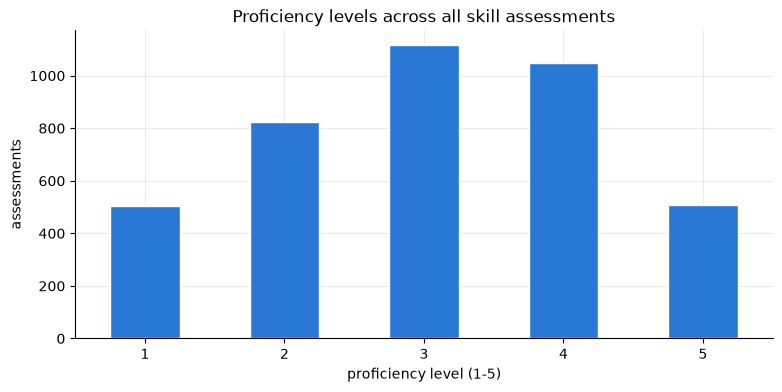

,average proficiency
category,
Domain,3.05
Leadership,3.07
Technical,3.07


In [22]:
skills = gold["skill_distribution"]
level = skills.groupby("proficiency_level")["employee_count"].sum()
ax = level.plot(kind="bar", color=BLUE, edgecolor="white")
ax.set_title("Proficiency levels across all skill assessments"); ax.set_xlabel("proficiency level (1-5)")
ax.set_ylabel("assessments"); ax.tick_params(axis="x", rotation=0)
plt.show()

skills["weighted"] = skills["proficiency_level"] * skills["employee_count"]
by_cat = skills.groupby("category")[["weighted", "employee_count"]].sum()
(by_cat["weighted"] / by_cat["employee_count"]).round(2).rename("average proficiency").to_frame()

In [23]:
comp = skills.groupby(["competency_name", "category"])[["weighted", "employee_count"]].sum()
comp["avg_proficiency"] = (comp["weighted"] / comp["employee_count"]).round(2)
comp = comp.reset_index().sort_values("avg_proficiency")
print("Weakest 5 competencies:"); print(comp.head(5)[["competency_name", "category", "avg_proficiency", "employee_count"]].to_string(index=False))
print("\nStrongest 5 competencies:"); print(comp.tail(5)[["competency_name", "category", "avg_proficiency", "employee_count"]].to_string(index=False))

Weakest 5 competencies:
       competency_name  category  avg_proficiency  employee_count
Stakeholder Management    Domain             2.62              92
           Negotiation    Domain             2.80             103
       Risk Management    Domain             2.87              94
      DevOps Practices Technical             2.88              86
       Market Analysis    Domain             2.91              99

Strongest 5 competencies:
      competency_name  category  avg_proficiency  employee_count
           API Design Technical             3.18             107
     Pricing Strategy    Domain             3.19              95
   Cloud Architecture Technical             3.20             102
         Localization    Domain             3.27             109
Regulatory Compliance    Domain             3.31              86


**Answer:** most assessments sit at proficiency **3–4**. The three categories are almost equal (average ≈ **3.05–3.07**),
so the real differences are per competency: weakest are **Stakeholder Management (2.62)**, **Negotiation**
and **Risk Management**; strongest are **Regulatory Compliance (3.31)**, **Localization** and **Cloud Architecture**. Combined with Q2,
this tells HR which skills to prioritise in the training budget.

## Assumptions & limitations

- **Snapshot data:** two review periods (2024-H2, 2025-H1) and one talent-review cycle, so "trend" means the change between two points.
- **Risk score** is a transparent rule-based score, not a trained model. The weights are documented above and easy to change.
- **Projects:** only 33 projects, so Q6 correlations are indicative only.
- **Quarantined rows** (143 learning events) are excluded from Gold; they can be inspected in `quarantine/learning_activity/`.